In [1]:
import numpy as np
import cv2
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
import pandas as pd
import os
from sklearn.utils.class_weight import compute_class_weight

In [2]:
img_arr = cv2.imread('/kaggle/input/datasets/mohitsngh/dataset/dataset/test/Happy/test_0012_aligned.jpg')
img_arr.shape

(100, 100, 3)

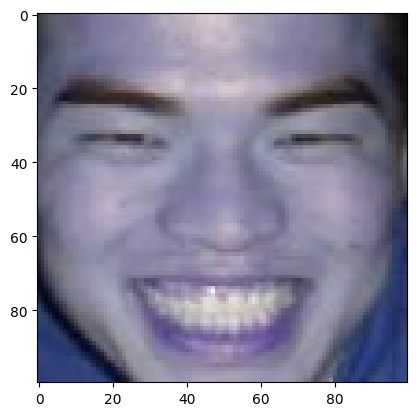

In [3]:
plt.imshow(img_arr)

In [4]:
train_dir = '/kaggle/input/datasets/mohitsngh/dataset/dataset/train'
test_dir = '/kaggle/input/datasets/mohitsngh/dataset/dataset/test'

In [5]:
img_size = (224, 224)
batch = 32
seed = 42

In [6]:
# loading the trainning data for the model training.....
# Splitting the trainning data into train and and validation data.....
train_df = tf.keras.utils.image_dataset_from_directory(
    train_dir,image_size = img_size,
    batch_size = batch, label_mode = 'categorical',
    seed = seed, validation_split = 0.15, subset = 'training'
)

val_df = tf.keras.utils.image_dataset_from_directory(
    train_dir,image_size = img_size, validation_split = 0.15,
    batch_size = batch, label_mode = 'categorical',
    subset = 'validation', seed = seed
)

Found 11273 files belonging to 5 classes.
Using 9583 files for training.


I0000 00:00:1792327485.878150      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792327485.882364      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 11273 files belonging to 5 classes.
Using 1690 files for validation.


In [7]:
# # loading the testing data for the model testing.....
test_df = tf.keras.utils.image_dataset_from_directory(
    test_dir,image_size = img_size,
    batch_size = batch, label_mode = 'categorical', shuffle = False
)

Found 2834 files belonging to 5 classes.


In [8]:
print(
    train_df.class_names,
    test_df.class_names
)

['Angry', 'Happy', 'Neutral', 'Sad', 'Surprise'] ['Angry', 'Happy', 'Neutral', 'Sad', 'Surprise']


In [9]:
# Adding the class weight as the dataset is unbalanced dataset.....
folderName = os.listdir('/kaggle/input/datasets/mohitsngh/dataset/dataset/train')
countImages = [len(os.listdir(f'{train_dir}/{folder}')) for folder in folderName] 
labels = np.concatenate([[i] * n for i, n in enumerate(countImages)])
weights = compute_class_weight("balanced", classes = np.arange(5), y = labels)
classWeight = dict(enumerate(weights))

In [10]:
classWeight

{0: np.float64(1.7477519379844961),
 1: np.float64(3.198014184397163),
 2: np.float64(0.8932646592709984),
 3: np.float64(1.1375378405650858),
 4: np.float64(0.47246437552388937)}

In [20]:
# Adding the agummentation to the images so slightly changed copies of your training images on the fly, 
# so the model sees more variety than the dataset really contains.
agument = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.15)
])

In [21]:
base =  EfficientNetB0(include_top = False, weights = "imagenet", input_shape = (224,224,3))
base.trainable = False

In [22]:
# Adding the layers.....
inputs = layers.Input(shape = (224,224,3))

x = augment(inputs)
x = base(x, training = False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(5, activation = "softmax")(x)

In [23]:
model = models.Model(inputs, outputs)

In [24]:
loss_fn = tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1)

In [25]:
# PHASE 1 Training the model
model.compile(optimizer = tf.keras.optimizers.Adam(1e-3), loss = loss_fn, metrics=["accuracy"])
cb2 = [
    tf.keras.callbacks.EarlyStopping(patience = 5, restore_best_weights = True),
    tf.keras.callbacks.ReduceLROnPlateau(factor = 0.5, patience=2, verbose = 1),
    tf.keras.callbacks.ModelCheckpoint('facial_model_raf_best.keras', save_best_only = True),
]

In [26]:
model.fit(
    train_df, validation_data = val_df, epochs = 15,
    class_weight = classWeight, callbacks = cb2
)

Epoch 1/15


E0000 00:00:1792327566.413848      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_2_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


300/300 ━━━━━━━━━━━━━━━━━━━━ 43s 97ms/step - accuracy: 0.4584 - loss: 2.6107 - val_accuracy: 0.5568 - val_loss: 1.2019 - learning_rate: 0.0010
Epoch 2/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 26s 87ms/step - accuracy: 0.4917 - loss: 2.0248 - val_accuracy: 0.5645 - val_loss: 1.1787 - learning_rate: 0.0010
Epoch 3/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 26s 86ms/step - accuracy: 0.5023 - loss: 1.8693 - val_accuracy: 0.5556 - val_loss: 1.1823 - learning_rate: 0.0010
Epoch 4/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 26s 88ms/step - accuracy: 0.5159 - loss: 1.8251 - val_accuracy: 0.5763 - val_loss: 1.1553 - learning_rate: 0.0010
Epoch 5/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 26s 85ms/step - accuracy: 0.5159 - loss: 1.8079 - val_accuracy: 0.5781 - val_loss: 1.1576 - learning_rate: 0.0010
Epoch 6/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 26s 88ms/step - accuracy: 0.5201 - loss: 1.7908 - val_accuracy: 0.5828 - val_loss: 1.1444 - learning_rate: 0.0010
Epoch 7/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 27s 88ms/step - accuracy: 0.5343 - loss: 1.7723

In [27]:
# PHASE 2 Training
base.trainable = True
for layer in base.layers[:-60]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False


In [28]:
model.compile(optimizer=tf.keras.optimizers.Adam(2e-5), loss = loss_fn, metrics=["accuracy"])

In [29]:
model.fit(
    train_df, validation_data = val_df, 
    epochs = 30,class_weight = classWeight, 
    callbacks = cb2
)

Epoch 1/30


E0000 00:00:1792327976.898425      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_2_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


300/300 ━━━━━━━━━━━━━━━━━━━━ 49s 120ms/step - accuracy: 0.5883 - loss: 1.6443 - val_accuracy: 0.6710 - val_loss: 1.0206 - learning_rate: 2.0000e-05
Epoch 2/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 34s 112ms/step - accuracy: 0.6167 - loss: 1.5808 - val_accuracy: 0.6917 - val_loss: 0.9871 - learning_rate: 2.0000e-05
Epoch 3/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 33s 111ms/step - accuracy: 0.6450 - loss: 1.5256 - val_accuracy: 0.6941 - val_loss: 0.9674 - learning_rate: 2.0000e-05
Epoch 4/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 33s 112ms/step - accuracy: 0.6533 - loss: 1.4997 - val_accuracy: 0.7154 - val_loss: 0.9348 - learning_rate: 2.0000e-05
Epoch 5/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - accuracy: 0.6752 - loss: 1.4642 - val_accuracy: 0.7166 - val_loss: 0.9414 - learning_rate: 2.0000e-05
Epoch 6/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 33s 111ms/step - accuracy: 0.6828 - loss: 1.4455 - val_accuracy: 0.7331 - val_loss: 0.9147 - learning_rate: 2.0000e-05
Epoch 7/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 33s 111ms/step - 

89/89 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.7996 - loss: 0.8026
Test accuracy: 0.800
89/89 ━━━━━━━━━━━━━━━━━━━━ 10s 88ms/step
              precision    recall  f1-score   support

       Angry       0.81      0.66      0.73       162
       Happy       0.83      0.94      0.88      1185
     Neutral       0.73      0.74      0.73       680
         Sad       0.76      0.72      0.74       478
     Suprise       0.91      0.59      0.72       329

    accuracy                           0.80      2834
   macro avg       0.81      0.73      0.76      2834
weighted avg       0.80      0.80      0.79      2834



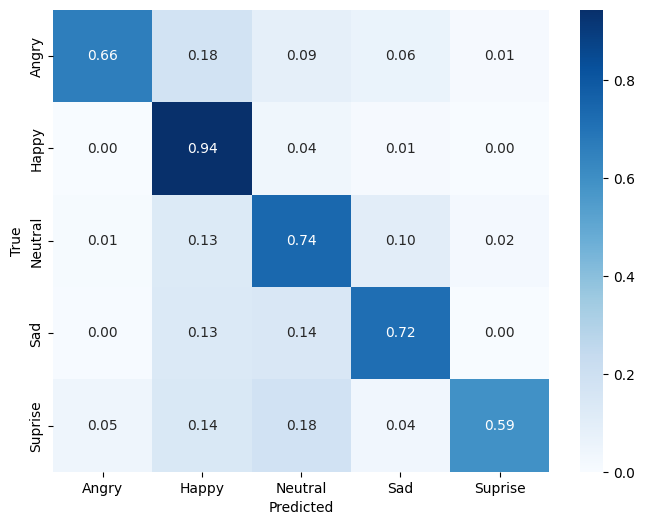

In [30]:
# MODEL EVALUATION
from sklearn.metrics import classification_report, confusion_matrix
class_names = ['Angry', 'Happy', 'Neutral', 'Sad', 'Suprise']
model = tf.keras.models.load_model('/kaggle/working/facial_model_raf_best.keras')
loss, acc = model.evaluate(test_df)
print(f"Test accuracy: {acc:.3f}")

y_true = np.concatenate([np.argmax(y, axis = 1) for _, y in test_df])
y_pred = np.argmax(model.predict(test_df), axis = 1)
print(classification_report(y_true, y_pred, target_names = class_names))

cm = confusion_matrix(y_true, y_pred, normalize = "true")
plt.figure(figsize = (8,6))
sns.heatmap(cm, annot = True, fmt = ".2f", cmap = "Blues",
            xticklabels = class_names, yticklabels = class_names)

plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

In [31]:
import numpy as np, tensorflow as tf
from sklearn.metrics import f1_score, classification_report

model = tf.keras.models.load_model("/kaggle/working/facial_model_raf_best.keras")
names = train_df.class_names
print(names)

def tta(ds):
    p1 = model.predict(ds, verbose=0)
    p2 = model.predict(ds.map(lambda x, y: (tf.image.flip_left_right(x), y)), verbose=0)
    return (p1 + p2) / 2

# validation probabilities + labels (val_ds is shuffled, so collect both in one pass)
probs, ys = [], []
for x, y in val_df:
    p = (model.predict(x, verbose=0) +
         model.predict(tf.image.flip_left_right(x), verbose=0)) / 2
    probs.append(p); ys.append(np.argmax(y.numpy(), axis=1))
probs, ys = np.concatenate(probs), np.concatenate(ys)

ia   = names.index("Angry")
isur = [i for i, n in enumerate(names) if n.lower().startswith("su")][0]

best = (0, 1.0, 1.0)
for sa in np.arange(1.0, 2.01, 0.1):
    for ss in np.arange(1.0, 2.51, 0.1):
        s = np.ones(len(names)); s[ia] = sa; s[isur] = ss
        f1 = f1_score(ys, np.argmax(probs * s, axis=1), average="macro")
        if f1 > best[0]:
            best = (f1, sa, ss)
print("val macro F1, angry scale, surprise scale:", best)

scale = np.ones(len(names)); scale[ia] = best[1]; scale[isur] = best[2]
y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_df])
y_pred = np.argmax(tta(test_df) * scale, axis=1)
print("Test accuracy:", (y_pred == y_true).mean())
print(classification_report(y_true, y_pred, target_names=names))

['Angry', 'Happy', 'Neutral', 'Sad', 'Surprise']
val macro F1, angry scale, surprise scale: (0.7616966717201025, np.float64(1.7000000000000006), np.float64(2.5000000000000013))
Test accuracy: 0.808045165843331
              precision    recall  f1-score   support

       Angry       0.77      0.70      0.73       162
       Happy       0.85      0.94      0.89      1185
     Neutral       0.75      0.71      0.73       680
         Sad       0.78      0.71      0.74       478
    Surprise       0.80      0.73      0.76       329

    accuracy                           0.81      2834
   macro avg       0.79      0.76      0.77      2834
weighted avg       0.80      0.81      0.80      2834

